## RQ3: Predicting flight delays

### Setup and imports

In [2]:
from pathlib import Path
import sys
import json

from sklearn.model_selection import ParameterGrid

import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
from xgboost import XGBClassifier

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import CLEAN_PARQUET, TABLES_DIR
from src.data_loading import load_flights

In [3]:
FLIGHTS_SRC = "flights_2024_clean.parquet"

BASELINE_COLS = [
    ("route_past_delay_rate", "derived from training data separately for each split"),
]
FLIGHT_COLS = [  # standard features from the original flight dataframe
    ("month", FLIGHTS_SRC),
    ("day_of_week", FLIGHTS_SRC),
    ("sched_hour", f"{FLIGHTS_SRC}: crs_dep_time // 100"),
    ("op_unique_carrier", FLIGHTS_SRC),
    ("distance", FLIGHTS_SRC),
]
RQ1_COLS = [
    ("route_cluster", "rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier)"),
    ("cluster_past_delay_rate", "rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster)"),
]
RQ2_COLS = [
    ("origin_community", "03_airports.csv: louvain (joined on origin)"),
    ("dest_community", "03_airports.csv: louvain (joined on dest)"),
    ("crosses_community", "derived: origin_community != dest_community"),
    ("origin_betweenness", "03_airports.csv: betweenness (joined on origin)"),
    ("dest_betweenness", "03_airports.csv: betweenness (joined on dest)"),
]
OTHER_COLS = [  # not features: route key for the baseline, and the target
    ("origin", FLIGHTS_SRC),
    ("dest", FLIGHTS_SRC),
    ("late_arrival", f"target, {FLIGHTS_SRC}: arr_delay >= 15"),
]

ROUTE_KEYS = ["origin", "dest", "op_unique_carrier"]

BASELINE_FEATURES = [column for column, _ in BASELINE_COLS]
FLIGHT_FEATURES = [column for column, _ in FLIGHT_COLS]
RQ1_FEATURES = [column for column, _ in RQ1_COLS]
RQ2_FEATURES = [column for column, _ in RQ2_COLS]


In [4]:
# Delay columns are loaded only to build the target, never as features.
flights = load_flights(
    CLEAN_PARQUET,
    columns=["month", "day_of_week", "op_unique_carrier", "origin", "dest",
             "crs_dep_time", "distance", "status", "arr_delay"],
)

# Cancelled and diverted flights have no arrival delay.
flights = flights[flights["status"] == "completed"].dropna(subset=["arr_delay"]).reset_index(drop=True)

# Late = arrives 15+ minutes late (official FAA definition).
flights["late_arrival"] = (flights["arr_delay"] >= 15).astype(int)
flights["sched_hour"] = ((flights["crs_dep_time"] // 100) % 24).astype(int)
flights = flights.drop(columns=["status", "arr_delay", "crs_dep_time"])

# RQ1 output: route + airline -> cluster, and the cluster's past delay rate.
route_lookup = pd.read_csv(TABLES_DIR / "rq1_route_clusters_jan_jun.csv")
route_rates = pd.read_csv(TABLES_DIR / "rq1_cluster_delay_rates_jan_jun.csv")[
    ["route_cluster", "historical_delay_rate"]
].rename(columns={"historical_delay_rate": "cluster_past_delay_rate"})

flights = flights.merge(route_lookup, on=ROUTE_KEYS, how="left", validate="many_to_one")
flights = flights.merge(route_rates, on="route_cluster", how="left", validate="many_to_one")

# Routes not seen in Jan-Jun have no cluster.
flights["route_cluster"] = flights["route_cluster"].astype("Int64").astype("string").fillna("unknown")

# RQ2 output: community and betweenness of the origin and of the destination airport.
airports = pd.read_csv(TABLES_DIR / "03_airports.csv")[["airport", "louvain", "betweenness"]]
for side in ["origin", "dest"]:
    side_features = airports.rename(columns={
        "airport": side,
        "louvain": f"{side}_community",
        "betweenness": f"{side}_betweenness",
    })
    flights = flights.merge(side_features, on=side, how="left", validate="many_to_one")
    flights[f"{side}_community"] = flights[f"{side}_community"].astype("Int64").astype("string").fillna("unknown")

flights["crosses_community"] = (flights["origin_community"] != flights["dest_community"]).astype(int)

rq3_df = flights[["origin", "dest"] + FLIGHT_FEATURES + RQ1_FEATURES + RQ2_FEATURES + ["late_arrival"]].copy()

print(f"RQ3 modeling dataframe rows: {len(rq3_df):,}")
print(f"Target rate: {rq3_df['late_arrival'].mean():.3%}")
print(f"Unknown route cluster: {(rq3_df['route_cluster'] == 'unknown').mean():.2%}")
print(f"Unknown origin / dest community: {(rq3_df['origin_community'] == 'unknown').mean():.2%} / {(rq3_df['dest_community'] == 'unknown').mean():.2%}")


feature_groups = [
    ("Baseline", BASELINE_COLS),
    ("standard_flight", FLIGHT_COLS),
    ("RQ1", RQ1_COLS),
    ("RQ2", RQ2_COLS),
    ("Other (not features)", OTHER_COLS),
]
for name, cols in feature_groups:
    print(f"{name}")
    for col, src in cols:
        print(f"    {col:<24} <- {src}")

# Dataset columns are accounted for; route keys and the target are not model features.
listed = [c for c, _ in FLIGHT_COLS + RQ1_COLS + RQ2_COLS + OTHER_COLS]
assert sorted(listed) == sorted(rq3_df.columns)


RQ3 modeling dataframe rows: 6,965,246
Target rate: 20.817%
Unknown route cluster: 1.83%
Unknown origin / dest community: 0.00% / 0.00%
Baseline
    route_past_delay_rate    <- derived from training data separately for each split
standard_flight
    month                    <- flights_2024_clean.parquet
    day_of_week              <- flights_2024_clean.parquet
    sched_hour               <- flights_2024_clean.parquet: crs_dep_time // 100
    op_unique_carrier        <- flights_2024_clean.parquet
    distance                 <- flights_2024_clean.parquet
RQ1
    route_cluster            <- rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier)
    cluster_past_delay_rate  <- rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster)
RQ2
    origin_community         <- 03_airports.csv: louvain (joined on origin)
    dest_community           <- 03_airports.csv: louvain (joined on dest)
    crosses_community        <- derived: origin_communit

### Feature groups

In [5]:
for name, features in [
    ("Baseline", BASELINE_FEATURES),
    ("standard_flight", FLIGHT_FEATURES),
    ("RQ1", RQ1_FEATURES),
    ("RQ2", RQ2_FEATURES),
]:
    print(f"{name}: {features}")

Baseline: ['route_past_delay_rate']
standard_flight: ['month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance']
RQ1: ['route_cluster', 'cluster_past_delay_rate']
RQ2: ['origin_community', 'dest_community', 'crosses_community', 'origin_betweenness', 'dest_betweenness']


### Feature configurations
These eight configurations are preserved exactly. The names `Baseline + RQ1`,
`Baseline + RQ2`, and `Baseline + RQ1 + RQ2` also include `standard_flight`;
inspect the table below for the exact inputs.


In [6]:
# Helper function to combine features without duplicates
def combine_features(*feature_lists):
    return list(dict.fromkeys(
        col
        for features in feature_lists
        for col in features
    ))


FEATURE_CONFIGS = {
    "Baseline": BASELINE_FEATURES,
    "standard_flight": FLIGHT_FEATURES,
    "RQ1": RQ1_FEATURES,
    "RQ2": RQ2_FEATURES,

    "Baseline + standard_flight": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES
    ),

    "Baseline + RQ1": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ1_FEATURES
    ),

    "Baseline + RQ2": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ2_FEATURES
    ),

    "Baseline + RQ1 + RQ2": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ1_FEATURES,
        RQ2_FEATURES
    )
}

In [7]:
assert len(FEATURE_CONFIGS) == 8
feature_config_table = pd.DataFrame([
    {"Feature Config": name, "Number of Features": len(features),
     "Features": ", ".join(features)}
    for name, features in FEATURE_CONFIGS.items()
])
display(feature_config_table)


,Feature Config,Number of Features,Features
0,Baseline,1,route_past_delay_rate
1,standard_flight,5,"month, day_of_week, sched_hour, op_unique_carr..."
2,RQ1,2,"route_cluster, cluster_past_delay_rate"
3,RQ2,5,"origin_community, dest_community, crosses_comm..."
4,Baseline + standard_flight,6,"route_past_delay_rate, month, day_of_week, sch..."
5,Baseline + RQ1,8,"route_past_delay_rate, month, day_of_week, sch..."
6,Baseline + RQ2,11,"route_past_delay_rate, month, day_of_week, sch..."
7,Baseline + RQ1 + RQ2,13,"route_past_delay_rate, month, day_of_week, sch..."


### Expanding-window feature selection
Each configuration is fitted from scratch twice:

| Fold | Training months | Validation month |
| --- | --- | --- |
| July | 1–6 | 7 |
| August | 1–7 | 8 |


In [8]:
VALIDATION_FOLDS = (
    {"fold": "July", "train_months": tuple(range(1, 7)), "validation_month": 7},
    {"fold": "August", "train_months": tuple(range(1, 8)), "validation_month": 8},
)
MODEL_TYPE = "EBM"
SELECTION_METRIC = "PR-AUC"
RANDOM_STATE = 42
# None fits every training row. Set e.g. 200_000 for a quicker comparison;
# all configurations then receive the same sample within each fold.
SAMPLE_SIZE = 200_000
THRESHOLD = 0.5


def make_model(model_type=MODEL_TYPE, random_state=RANDOM_STATE):
    if model_type == "EBM":
        return ExplainableBoostingClassifier(random_state=random_state, interactions=0)
    if model_type == "XGBoost":
        return XGBClassifier(
            n_estimators=100, max_depth=6, enable_categorical=True,
            tree_method="hist", random_state=random_state,
            eval_metric="logloss",
        )
    raise ValueError("model_type must be 'EBM' or 'XGBoost'")


def add_historical_rate(
    train, val, keys, output_col, smoothing=20, initial_prior=0.5
):
    """Training: earlier months only. Validation: full training history."""
    train = train.copy()
    val = val.copy()

    if train.empty:
        raise ValueError("Training data must not be empty")
    if train["month"].isna().any() or val["month"].isna().any():
        raise ValueError("Month must not be missing")
    if not val.empty and train["month"].max() >= val["month"].min():
        raise ValueError("Validation must follow the training months")
    if smoothing < 0:
        raise ValueError("smoothing must be non-negative")

    def encode(history, rows):
        if history.empty:
            # Fixed prior: do not estimate it from future outcomes.
            return pd.Series(initial_prior, index=rows.index, dtype=float)

        prior = history["late_arrival"].mean()

        # Unknown cluster membership is not a meaningful shared cluster.
        if keys == ["route_cluster"]:
            history = history.loc[
                history["route_cluster"].notna()
                & history["route_cluster"].ne("unknown")
            ]

        stats = (
            history.groupby(keys, observed=True, dropna=False)["late_arrival"]
            .agg(["sum", "count"])
            .reset_index()
        )
        stats["_rate"] = (
            stats["sum"] + smoothing * prior
        ) / (stats["count"] + smoothing)

        # Left merge preserves row order; restore the original index.
        encoded = rows[keys].merge(
            stats[keys + ["_rate"]],
            on=keys,
            how="left",
            validate="many_to_one",
            sort=False,
        )["_rate"].fillna(prior)

        return pd.Series(encoded.to_numpy(), index=rows.index)

    train[output_col] = float(initial_prior)

    for month in sorted(train["month"].unique()):
        mask = train["month"].eq(month)
        history = train.loc[train["month"] < month]
        train.loc[mask, output_col] = encode(
            history, train.loc[mask]
        )

    val[output_col] = encode(train, val)
    return train, val


def prepare_fold(df, fold, sample_size=None, random_state=42):
    train = df[df["month"].isin(fold["train_months"])].copy()
    val = df[df["month"] == fold["validation_month"]].copy()
    if train.empty or val.empty:
        raise ValueError(f"Empty training or validation data for {fold['fold']}")
    missing_months = set(fold["train_months"]) - set(train["month"].unique())
    if missing_months:
        raise ValueError(f"Missing training months: {sorted(missing_months)}")
    if train["late_arrival"].nunique() != 2 or val["late_arrival"].nunique() != 2:
        raise ValueError("Both target classes are required in training and validation")
    train, val = add_historical_rate(train, val, ROUTE_KEYS, "route_past_delay_rate")
    train, val = add_historical_rate(train, val, ["route_cluster"], "cluster_past_delay_rate")
    n_available = len(train)
    if sample_size is not None:
        if sample_size < 2:
            raise ValueError("sample_size must be at least 2 or None")
        if len(train) > sample_size:
            train = train.sample(n=sample_size, random_state=random_state)
    if train["late_arrival"].nunique() != 2:
        raise ValueError("Training sample must contain both target classes")
    # Learn categorical vocabularies from training only. Unseen validation
    # categories become missing values, supported by both estimators.
    all_features = list(dict.fromkeys(f for fs in FEATURE_CONFIGS.values() for f in fs))
    for col in all_features:
        if (pd.api.types.is_object_dtype(train[col])
                or isinstance(train[col].dtype, (pd.StringDtype, pd.CategoricalDtype))):
            categories = pd.Index(train[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=categories)
            train[col] = train[col].astype(dtype)
            val[col] = val[col].astype(dtype)
    return train, val, n_available


def evaluate_model(model, X, y, threshold=0.5):
    probs = model.predict_proba(X)[:, 1]
    preds = (probs >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y, probs),
        "PR-AUC": average_precision_score(y, probs),
        "Log Loss": log_loss(y, probs, labels=[0, 1]),
        "Brier Score": brier_score_loss(y, probs),
        "Accuracy": accuracy_score(y, preds),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1": f1_score(y, preds, zero_division=0),
    }


def run_feature_selection(df, model_type=MODEL_TYPE, sample_size=SAMPLE_SIZE):
    rows = []
    for fold in VALIDATION_FOLDS:
        train, val, n_available = prepare_fold(df, fold, sample_size, RANDOM_STATE)
        for name, features in FEATURE_CONFIGS.items():
            print(f"{model_type} | {name} | train 1–{max(fold['train_months'])} → validate {fold['validation_month']}")
            model = make_model(model_type, RANDOM_STATE)
            start = time.perf_counter()
            model.fit(train[features], train["late_arrival"])
            duration = time.perf_counter() - start
            for split, data in (("Train", train), ("Validation", val)):
                rows.append({
                    "Estimator": model_type, "Feature Config": name,
                    "Number of Features": len(features), "Fold": fold["fold"],
                    "Train Period": f"1–{max(fold['train_months'])}",
                    "Validation Month": fold["validation_month"], "Split": split,
                    "Available Train Samples": n_available, "Train Samples": len(train),
                    "Eval Samples": len(data), "Training Seconds": duration,
                    **evaluate_model(model, data[features], data["late_arrival"], THRESHOLD),
                })
            # Only results are retained, avoiding 16 large fitted models in memory.
    results = pd.DataFrame(rows)
    assert len(results) == len(FEATURE_CONFIGS) * len(VALIDATION_FOLDS) * 2
    return results


In [9]:
# WARNING : This takes a shit ton of time
results_df = run_feature_selection(rq3_df, model_type=MODEL_TYPE, sample_size=SAMPLE_SIZE)
validation_results = results_df[results_df["Split"] == "Validation"].copy()
display(validation_results.round(4))


C:\Users\huste\AppData\Local\Temp\ipykernel_358268\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
C:\Users\huste\AppData\Local\Temp\ipykernel_358268\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)


EBM | Baseline | train 1–6 → validate 7
EBM | standard_flight | train 1–6 → validate 7


KeyboardInterrupt: 

### Rank the feature configurations
Rank feature configurations by mean validation PR-AUC across the two groups

All other metrics, fold variability, and the train–validation gap are reported for comparison but do not affect the ranking.


In [ ]:
SELECTION_METRIC = "Recall"

METRICS = [
    "PR-AUC", "ROC-AUC", "Log Loss", "Brier Score",
    "Accuracy", "Precision", "Recall", "F1"
]

means = (
    validation_results.groupby("Feature Config", sort=False)[METRICS]
    .mean()
    .add_prefix("Mean Validation ")
)

per_fold = validation_results.pivot(
    index="Feature Config",
    columns="Validation Month",
    values=SELECTION_METRIC,
).rename(columns={7: "July Recall", 8: "August Recall"})

ranking = means.join(per_fold)

ranking["Validation Recall SD"] = (
    validation_results.groupby("Feature Config")[SELECTION_METRIC].std()
)
ranking["Number of Features"] = pd.Series({
    name: len(features) for name, features in FEATURE_CONFIGS.items()
})

train_means = (
    results_df[results_df["Split"] == "Train"]
    .groupby("Feature Config")[SELECTION_METRIC]
    .mean()
)
ranking["Mean Train Recall"] = train_means
ranking["Train–Validation Recall Gap"] = (
    train_means - ranking["Mean Validation Recall"]
)

ranking = (
    ranking.reset_index()
    .sort_values(
        ["Mean Validation Recall", "Number of Features", "Feature Config"],
        ascending=[False, True, True],
        kind="stable",
    )
    .reset_index(drop=True)
)
ranking.insert(0, "Rank", range(1, len(ranking) + 1))

best_config = ranking.loc[0, "Feature Config"]
best_features = FEATURE_CONFIGS[best_config].copy()

print(f"Selected features for {MODEL_TYPE}: {best_config}")
print(f"Mean validation recall: {ranking.loc[0, 'Mean Validation Recall']:.4f}")
print(f"Features: {best_features}")

display(ranking.round(4))

Selected features for EBM: Baseline + RQ2
Mean validation recall: 0.0829
Features: ['route_past_delay_rate', 'month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance', 'origin_community', 'dest_community', 'crosses_community', 'origin_betweenness', 'dest_betweenness']


,Rank,Feature Config,Mean Validation PR-AUC,Mean Validation ROC-AUC,Mean Validation Log Loss,Mean Validation Brier Score,Mean Validation Accuracy,Mean Validation Precision,Mean Validation Recall,Mean Validation F1,July Recall,August Recall,Validation Recall SD,Number of Features,Mean Train Recall,Train–Validation Recall Gap
0,1,Baseline + RQ2,0.4051,0.6752,0.5498,0.1840,0.7324,0.4909,0.0829,0.1345,0.0339,0.1319,0.0693,11,0.0287,-0.0542
1,2,Baseline + RQ1 + RQ2,0.4044,0.6748,0.5494,0.1838,0.7324,0.4911,0.0827,0.1343,0.0344,0.1310,0.0683,13,0.0303,-0.0524
2,3,Baseline + standard_flight,0.4091,0.6762,0.5491,0.1837,0.7337,0.5184,0.0785,0.1286,0.0304,0.1267,0.0681,6,0.0243,-0.0542
3,4,Baseline + RQ1,0.4083,0.6760,0.5485,0.1835,0.7338,0.5170,0.0765,0.1260,0.0300,0.1230,0.0657,8,0.0260,-0.0505
4,5,standard_flight,0.4032,0.6702,0.5512,0.1845,0.7344,0.4497,0.0328,0.0580,0.0002,0.0654,0.0461,5,0.0062,-0.0266
5,6,Baseline,0.3332,0.5948,0.5733,0.1929,0.7342,0.4230,0.0043,0.0084,0.0056,0.0029,0.0019,1,0.0038,-0.0004
6,7,RQ1,0.2754,0.5191,0.5829,0.1965,0.7346,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2,0.0000,0.0000
7,8,RQ2,0.2955,0.5512,0.5822,0.1961,0.7346,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5,0.0000,0.0000


In [ ]:

selection_prefix = f"rq3_{MODEL_TYPE.lower()}_feature_selection"
results_df.to_csv(TABLES_DIR / f"{selection_prefix}_fold_scores.csv", index=False)
ranking.to_csv(TABLES_DIR / f"{selection_prefix}_ranking.csv", index=False)
selection = {
    "estimator": MODEL_TYPE, "feature_config": best_config, "features": best_features,
    "selection_metric": SELECTION_METRIC,
    "aggregation": "unweighted mean over validation months 7 and 8",
    "mean_validation_score": float(ranking.loc[0, "Mean Validation PR-AUC"]),
    "sample_size": SAMPLE_SIZE, "random_state": RANDOM_STATE,
    "folds": list(VALIDATION_FOLDS), "reserved_test_months": [9, 10, 11, 12],
}
(TABLES_DIR / f"{selection_prefix}_selected.json").write_text(json.dumps(selection, indent=2))
print(f"Saved {selection_prefix} results and selected features to {TABLES_DIR}")


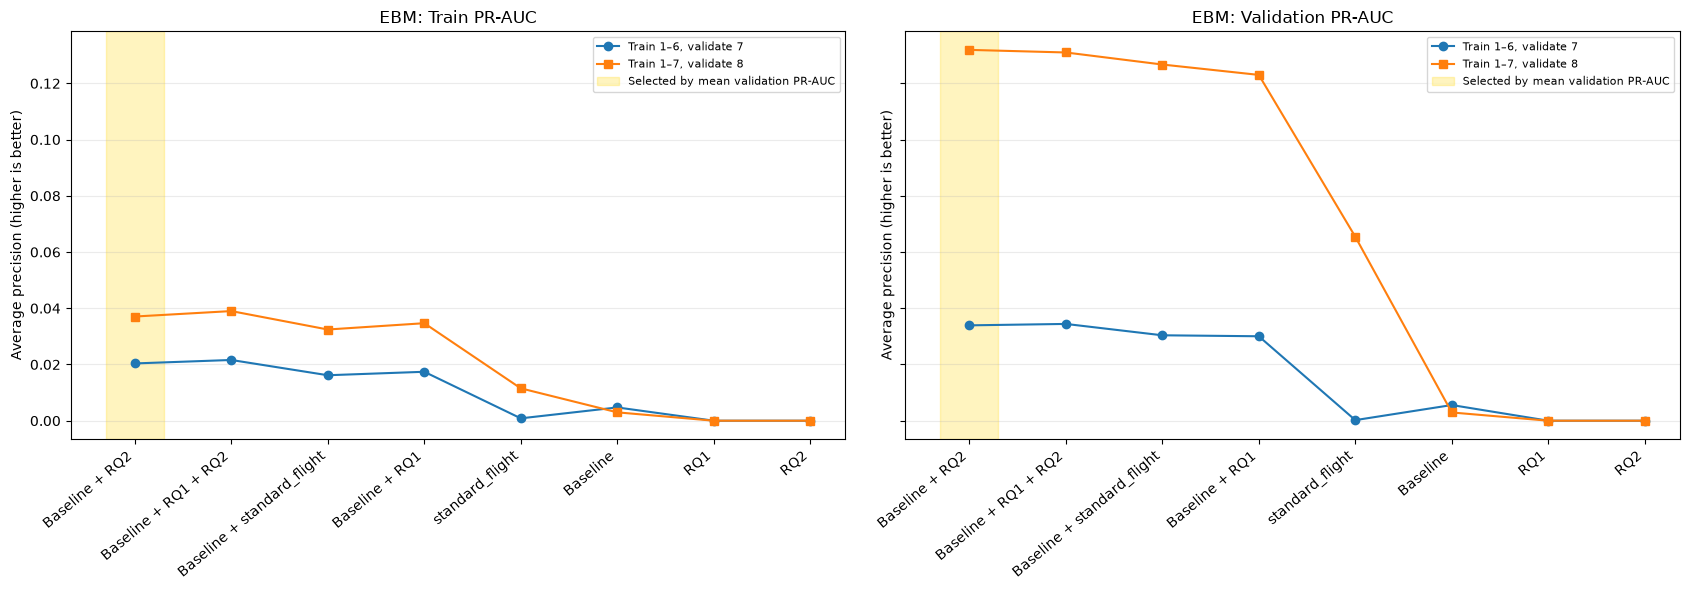

In [ ]:
# Same configuration order in both panels; highlight the validation-selected winner.
order = ranking["Feature Config"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, split in zip(axes, ["Train", "Validation"]):
    for month, marker in [(7, "o"), (8, "s")]:
        scores = results_df[(results_df["Split"] == split) & (results_df["Validation Month"] == month)].set_index("Feature Config")
        ax.plot(range(len(order)), scores.loc[order, SELECTION_METRIC], marker=marker,
                label=f"Train 1–{month - 1}, validate {month}")
    best_index = order.index(best_config)
    ax.axvspan(best_index - 0.3, best_index + 0.3, color="gold", alpha=0.25,
               label="Selected by mean validation PR-AUC")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=40, ha="right")
    ax.set_title(f"{MODEL_TYPE}: {split} PR-AUC")
    ax.set_ylabel("Average precision (higher is better)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


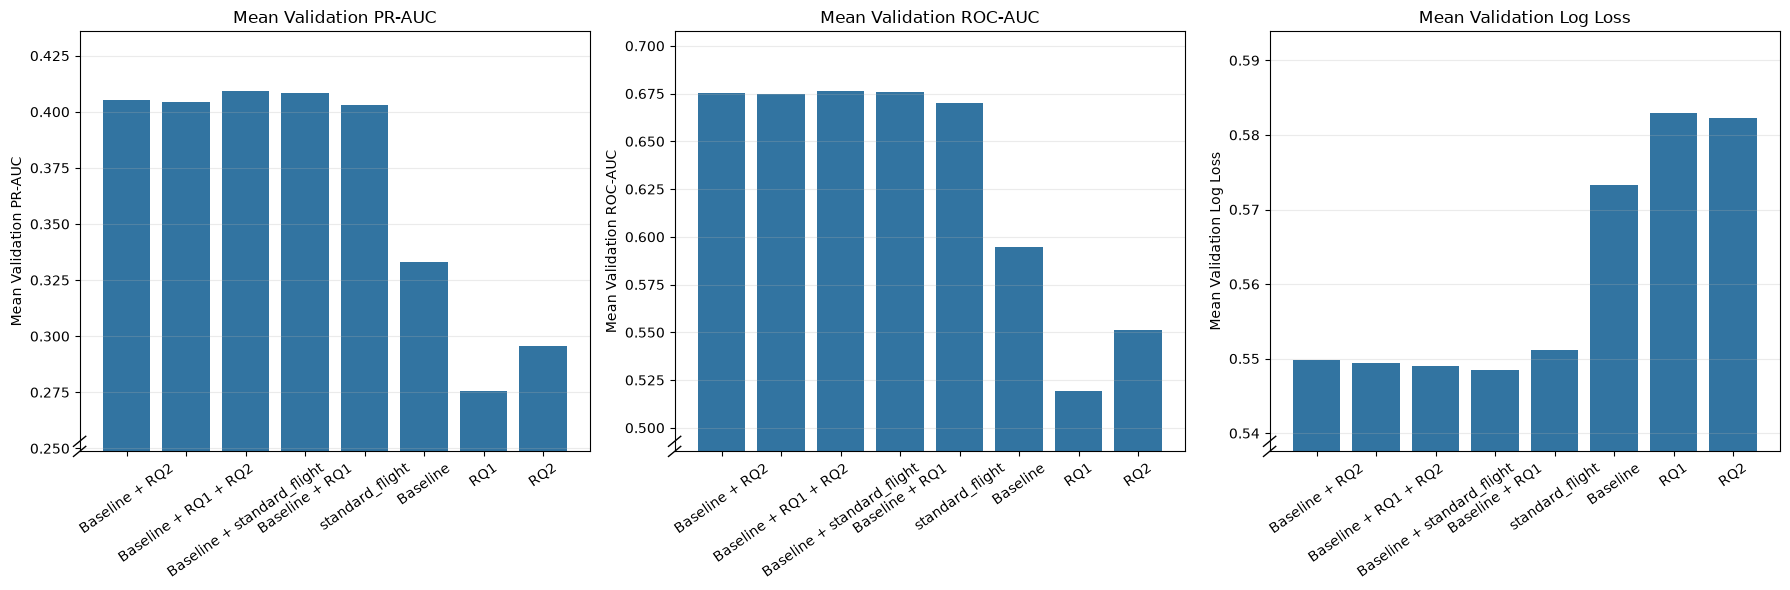

In [ ]:
metrics = [
    "Mean Validation PR-AUC",
    "Mean Validation ROC-AUC",
    "Mean Validation Log Loss",
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, metric in zip(axes, metrics):
    sns.barplot(
        data=ranking,
        x="Feature Config",
        y=metric,
        order=ranking["Feature Config"],
        ax=ax,
    )

    values = ranking[metric]
    low, high = values.min(), values.max()
    pad = max((high - low) * 0.2, abs(low) * 0.02, 0.001)
    ax.set_ylim(low - pad, high + pad)

    # Mark the truncated y-axis.
    d = 0.012
    ax.plot((-d, d), (-d, d), transform=ax.transAxes,
            color="black", clip_on=False, linewidth=1)
    ax.plot((-d, d), (d, 3 * d), transform=ax.transAxes,
            color="black", clip_on=False, linewidth=1)

    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

All the modesl with multiple features are almost iddentlically, so we have decided to continue with the "Baseline + RQ1 + RQ2"

In [ ]:
# Save results and the exact selected feature list for subsequent modeling.
TABLES_DIR = Path("../results")
TABLES_DIR.mkdir(parents=True, exist_ok=True)


Saved rq3_ebm_feature_selection results and selected features to ..\results


# Hyperparameter tuning

Select the EBM by mean July/August validation PR-AUC and its probability threshold by mean validation F1. F1 balances precision and recall but does not make them equal. September–December remain reserved for final evaluation. Tuning results are provisional because the existing structural features use fixed January–June lookups for all training rows.

Previously displayed notebook outputs may reflect the old selection. Re-run the tuning cell to refresh them, or read the updated saved rankings from `results/tables` without retraining.

In [ ]:
chosen_model = "Baseline + RQ1 + RQ2"


In [ ]:
# Edit these lists to choose a grid; each combination is fitted once per fold.
EBM_PARAM_GRID = {
    "learning_rate": [0.015, 0.03],
    "max_leaves": [2, 3],
    "min_samples_leaf": [4],
    "interactions": [0, 3],
}
EBM_FIXED_PARAMS = {"random_state": RANDOM_STATE}
PROBABILITY_THRESHOLDS = [0.1, 0.3, 0.5, 0.7]
TUNING_SAMPLE_SIZE = SAMPLE_SIZE  # None uses all available training rows.

# Show every parameter supported by the installed version, including defaults.
ebm_parameter_options = pd.DataFrame([
    {"Parameter": name, "Library default": repr(value),
     "Fixed value": repr(EBM_FIXED_PARAMS[name]) if name in EBM_FIXED_PARAMS else "",
     "Grid values": repr(EBM_PARAM_GRID[name]) if name in EBM_PARAM_GRID else ""}
    for name, value in ExplainableBoostingClassifier().get_params().items()
])
print(f"Probability thresholds: {PROBABILITY_THRESHOLDS}")
print(f"Model fits: {len(ParameterGrid(EBM_PARAM_GRID))} configurations × {len(VALIDATION_FOLDS)} folds")

,Parameter,Library default,Fixed value,Grid values
0,callback,None,,
1,cat_smooth,10.0,,
2,cyclic_progress,False,,
3,early_stopping_rounds,100,,
4,early_stopping_tolerance,1e-05,,
5,exclude,None,,
6,feature_names,None,,
7,feature_types,None,,
8,gain_scale,5.0,,
9,greedy_ratio,10.0,,


Probability thresholds: [0.1, 0.3, 0.5, 0.7]
Model fits: 8 configurations × 2 folds


In [ ]:
def run_ebm_grid_search(df, feature_name, folds, param_grid, fixed_params,
                        thresholds, sample_size, random_state):
    if feature_name not in FEATURE_CONFIGS:
        raise ValueError(f"Unknown feature configuration: {feature_name}")
    if not folds or not thresholds:
        raise ValueError("At least one fold and threshold are required")
    if any(not 0 <= threshold <= 1 for threshold in thresholds):
        raise ValueError("Probability thresholds must be between 0 and 1")
    overlap = set(param_grid) & set(fixed_params)
    if overlap:
        raise ValueError(f"Parameters cannot be both fixed and in the grid: {sorted(overlap)}")
    valid_params = set(ExplainableBoostingClassifier().get_params())
    invalid = (set(param_grid) | set(fixed_params)) - valid_params
    if invalid:
        raise ValueError(f"Unknown EBM parameters: {sorted(invalid)}")

    features = FEATURE_CONFIGS[feature_name]
    combinations = list(ParameterGrid(param_grid))
    model_rows, threshold_rows = [], []
    for fold in folds:
        train, val, available = prepare_fold(df, fold, sample_size, random_state)
        y = val["late_arrival"]
        for config_id, params in enumerate(combinations):
            print(f"{fold['fold']} | configuration {config_id + 1}/{len(combinations)} | {params}", flush=True)
            model = ExplainableBoostingClassifier(**fixed_params, **params)
            start = time.perf_counter()
            model.fit(train[features], train["late_arrival"])
            elapsed = time.perf_counter() - start
            probs = model.predict_proba(val[features])[:, 1]
            model_rows.append({
                "Configuration": config_id, "Fold": fold["fold"],
                "Validation Month": fold["validation_month"],
                "Available Train Samples": available, "Train Samples": len(train),
                "Validation Samples": len(val), "Training Seconds": elapsed,
                "ROC-AUC": roc_auc_score(y, probs),
                "PR-AUC": average_precision_score(y, probs),
                "Log Loss": log_loss(y, probs, labels=[0, 1]),
                **params,
            })
            for threshold in thresholds:
                predictions = probs >= threshold
                threshold_rows.append({
                    "Configuration": config_id, "Fold": fold["fold"],
                    "Validation Month": fold["validation_month"],
                    "Threshold": threshold,
                    "Recall": recall_score(y, predictions, zero_division=0),
                    "Precision": precision_score(y, predictions, zero_division=0),
                    "F1": f1_score(y, predictions, zero_division=0),
                    "Positive Prediction Rate": predictions.mean(),
                })
    return pd.DataFrame(model_rows), pd.DataFrame(threshold_rows)

tuning_folds, threshold_folds = run_ebm_grid_search(
    rq3_df, chosen_model, VALIDATION_FOLDS, EBM_PARAM_GRID, EBM_FIXED_PARAMS,
    PROBABILITY_THRESHOLDS, TUNING_SAMPLE_SIZE, RANDOM_STATE,
)

tuning_ranking = tuning_folds.groupby("Configuration", as_index=False).agg(
    Mean_ROC_AUC=("ROC-AUC", "mean"), Mean_PR_AUC=("PR-AUC", "mean"),
    Mean_log_loss=("Log Loss", "mean"), Mean_training_seconds=("Training Seconds", "mean"),
)
parameters = pd.DataFrame([{"Configuration": i, **p} for i, p in enumerate(ParameterGrid(EBM_PARAM_GRID))])
tuning_ranking = tuning_ranking.merge(parameters, on="Configuration", validate="one_to_one")
tuning_ranking = tuning_ranking.sort_values(["Mean_PR_AUC", "Configuration"], ascending=[False, True]).reset_index(drop=True)
interaction_comparison = tuning_ranking.groupby("interactions", as_index=False, sort=True).first()
best_configuration = int(tuning_ranking.loc[0, "Configuration"])
best_ebm_params = {**EBM_FIXED_PARAMS, **list(ParameterGrid(EBM_PARAM_GRID))[best_configuration]}

threshold_ranking = (
    threshold_folds[threshold_folds["Configuration"] == best_configuration]
    .groupby("Threshold", as_index=False)[["Recall", "Precision", "F1", "Positive Prediction Rate"]]
    .mean()
    .sort_values(["F1", "Threshold"], ascending=[False, False])
    .reset_index(drop=True)
)
best_threshold = float(threshold_ranking.loc[0, "Threshold"])
print(f"Selected EBM parameters: {best_ebm_params}")
print(f"Selected threshold by mean F1: {best_threshold}")
print("Best model for each interaction setting:")
display(interaction_comparison.round(4))
display(tuning_ranking.round(4))
display(tuning_folds.sort_values(["Configuration", "Validation Month"]).round(4))
display(threshold_ranking.round(4))

tuning_dir = PROJECT_DIR / "results" / "tables"
tuning_dir.mkdir(parents=True, exist_ok=True)
tuning_folds.to_csv(tuning_dir / "rq3_ebm_tuning_folds.csv", index=False)
tuning_ranking.to_csv(tuning_dir / "rq3_ebm_tuning_ranking.csv", index=False)
threshold_folds.to_csv(tuning_dir / "rq3_ebm_threshold_folds.csv", index=False)
threshold_ranking.to_csv(tuning_dir / "rq3_ebm_threshold_ranking.csv", index=False)
tuning_settings = {
    "feature_configuration": chosen_model, "features": FEATURE_CONFIGS[chosen_model],
    "model_metric": "mean PR-AUC", "threshold_metric": "mean F1",
    "best_configuration": best_configuration, "best_ebm_params": best_ebm_params,
    "best_threshold": best_threshold, "parameter_grid": EBM_PARAM_GRID,
    "thresholds": PROBABILITY_THRESHOLDS, "folds": list(VALIDATION_FOLDS),
    "sample_size": TUNING_SAMPLE_SIZE, "random_state": RANDOM_STATE,
    "warning": "Provisional: structural features use fixed January-June lookups for all rows.",
}
with (tuning_dir / "rq3_ebm_tuning_settings.json").open("w", encoding="utf-8") as file:
    json.dump(tuning_settings, file, indent=2)
print(f"Saved tuning results to {tuning_dir}")

July | configuration 1/8 | {'interactions': 0, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}


C:\Users\huste\AppData\Local\Temp\ipykernel_326940\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
C:\Users\huste\AppData\Local\Temp\ipykernel_326940\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)


July | configuration 2/8 | {'interactions': 0, 'learning_rate': 0.015, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 3/8 | {'interactions': 0, 'learning_rate': 0.03, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 4/8 | {'interactions': 0, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 5/8 | {'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 6/8 | {'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 7/8 | {'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 8/8 | {'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4}
August | configuration 1/8 | {'interactions': 0, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}


C:\Users\huste\AppData\Local\Temp\ipykernel_326940\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
c:\Users\huste\Documents\github\ComputationalToolsForDS\.venv\Lib\site-packages\interpret\glassbox\_ebm\_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


August | configuration 2/8 | {'interactions': 0, 'learning_rate': 0.015, 'max_leaves': 3, 'min_samples_leaf': 4}


c:\Users\huste\Documents\github\ComputationalToolsForDS\.venv\Lib\site-packages\interpret\glassbox\_ebm\_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


... (14 outputs left out)

,Configuration,Mean_ROC_AUC,Mean_PR_AUC,Mean_log_loss,Mean_training_seconds,interactions,learning_rate,max_leaves,min_samples_leaf
0,4,0.6791,0.4078,0.5478,24.5000,3,0.015,2,4
1,7,0.6793,0.4076,0.5473,7.1963,3,0.030,3,4
2,6,0.6790,0.4075,0.5481,16.1282,3,0.030,2,4
3,5,0.6793,0.4074,0.5474,9.4548,3,0.015,3,4
4,0,0.6748,0.4044,0.5494,17.2984,0,0.015,2,4
5,2,0.6748,0.4041,0.5494,13.0177,0,0.030,2,4
6,3,0.6748,0.4037,0.5486,4.9201,0,0.030,3,4
7,1,0.6748,0.4035,0.5491,6.3543,0,0.015,3,4


,Configuration,Fold,Validation Month,Available Train Samples,Train Samples,Validation Samples,Training Seconds,ROC-AUC,PR-AUC,Log Loss,interactions,learning_rate,max_leaves,min_samples_leaf
0,0,July,7,3403472,200000,613938,16.2285,0.6717,0.4356,0.5762,0,0.015,2,4
8,0,August,8,4017410,200000,604299,18.3682,0.6780,0.3731,0.5227,0,0.015,2,4
1,1,July,7,3403472,200000,613938,5.9511,0.6716,0.4348,0.5777,0,0.015,3,4
9,1,August,8,4017410,200000,604299,6.7576,0.6779,0.3723,0.5205,0,0.015,3,4
2,2,July,7,3403472,200000,613938,11.7603,0.6716,0.4353,0.5765,0,0.030,2,4
10,2,August,8,4017410,200000,604299,14.2751,0.6780,0.3729,0.5224,0,0.030,2,4
3,3,July,7,3403472,200000,613938,5.3660,0.6716,0.4350,0.5780,0,0.030,3,4
11,3,August,8,4017410,200000,604299,4.4743,0.6780,0.3725,0.5192,0,0.030,3,4
4,4,July,7,3403472,200000,613938,26.5587,0.6773,0.4410,0.5740,3,0.015,2,4
12,4,August,8,4017410,200000,604299,22.4414,0.6808,0.3746,0.5216,3,0.015,2,4


,Threshold,Recall,Precision,F1,Positive Prediction Rate
0,0.3,0.5970,0.3925,0.4660,0.4064
1,0.1,0.9726,0.2807,0.4338,0.9231
2,0.5,0.1287,0.4840,0.1905,0.0689
3,0.7,0.0031,0.4767,0.0062,0.0016


Saved tuning results to C:\Users\huste\Documents\github\ComputationalToolsForDS\results\tables


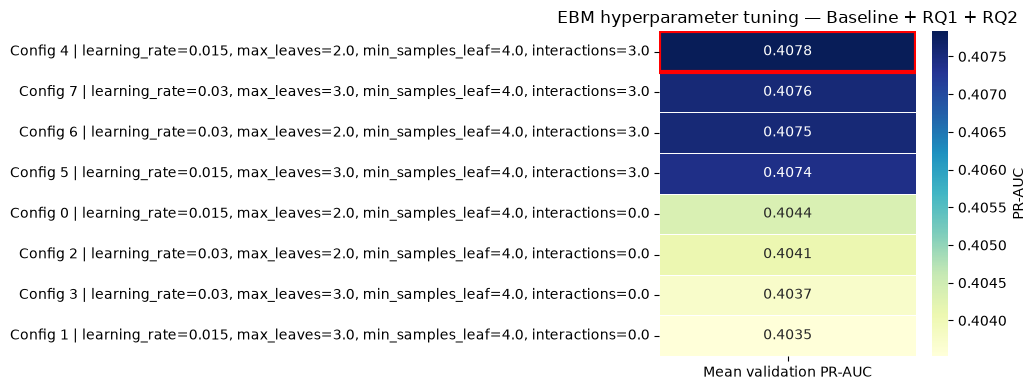

In [ ]:
# Include the varying hyperparameters in the row labels.
param_names = list(EBM_PARAM_GRID.keys())

heatmap_data = tuning_ranking.sort_values(
    "Mean_PR_AUC", ascending=False
).copy()

heatmap_data["Label"] = heatmap_data.apply(
    lambda row: (
        f"Config {int(row['Configuration'])} | "
        + ", ".join(f"{p}={row[p]}" for p in param_names)
    ),
    axis=1,
)

heatmap_data = heatmap_data.set_index("Label")[["Mean_PR_AUC"]]
heatmap_data.columns = ["Mean validation PR-AUC"]

fig, ax = plt.subplots(
    figsize=(10, max(4, len(heatmap_data) * 0.45))
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "PR-AUC"},
    ax=ax,
)

# Highest PR-AUC is the first row.
ax.add_patch(
    plt.Rectangle(
        (0, 0), 1, 1,
        fill=False, edgecolor="red", linewidth=3
    )
)

ax.set_title(f"EBM hyperparameter tuning — {chosen_model}")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# Show all hyperparameter tuning results
display(tuning_ranking)

,Configuration,Mean_ROC_AUC,Mean_PR_AUC,Mean_log_loss,Mean_training_seconds,interactions,learning_rate,max_leaves,min_samples_leaf
0,4,0.679086,0.407833,0.547761,24.500021,3,0.015,2,4
1,7,0.679335,0.407559,0.547295,7.196272,3,0.030,3,4
2,6,0.678976,0.407547,0.548076,16.128181,3,0.030,2,4
3,5,0.679302,0.407400,0.547444,9.454828,3,0.015,3,4
4,0,0.674836,0.404368,0.549421,17.298360,0,0.015,2,4
5,2,0.674773,0.404096,0.549437,13.017666,0,0.030,2,4
6,3,0.674839,0.403744,0.548621,4.920147,0,0.030,3,4
7,1,0.674759,0.403529,0.549096,6.354328,0,0.015,3,4


In [ ]:
from sklearn.model_selection import ParameterGrid

CONFIGURATION_ID = 4
METRICS = [
    "PR-AUC", "ROC-AUC", "Log Loss", "Brier Score",
    "Accuracy", "Precision", "Recall", "F1",
]
tuning_dir = PROJECT_DIR / "results" / "tables"
with (tuning_dir / "rq3_ebm_tuning_settings.json").open(encoding="utf-8") as file:
    saved_tuning = json.load(file)

# Defaults to the winning model's threshold; change it to compare another threshold.
CONFIG_THRESHOLD = saved_tuning["best_threshold"]
if not 0 <= CONFIG_THRESHOLD <= 1:
    raise ValueError("CONFIG_THRESHOLD must be between 0 and 1")

saved_grid = list(ParameterGrid(saved_tuning["parameter_grid"]))
if CONFIGURATION_ID < 0 or CONFIGURATION_ID >= len(saved_grid):
    raise ValueError(f"Configuration {CONFIGURATION_ID} is not in the saved grid")
config_params = {
    key: value for key, value in saved_tuning["best_ebm_params"].items()
    if key not in saved_tuning["parameter_grid"]
}
config_params.update(saved_grid[CONFIGURATION_ID])
config_features = saved_tuning["features"]

config_metric_rows = []
for fold in saved_tuning["folds"]:
    train, val, available = prepare_fold(
        rq3_df, fold, saved_tuning["sample_size"], saved_tuning["random_state"]
    )
    model = ExplainableBoostingClassifier(**config_params)
    model.fit(train[config_features], train["late_arrival"])
    scores = evaluate_model(model, val[config_features], val["late_arrival"], CONFIG_THRESHOLD)
    config_metric_rows.append({
        "Fold": fold["fold"], "Validation Month": fold["validation_month"],
        "Train Samples": len(train), "Validation Samples": len(val),
        "Threshold": CONFIG_THRESHOLD, **{metric: scores[metric] for metric in METRICS},
    })

config_metrics = pd.DataFrame(config_metric_rows)
config_mean = config_metrics[METRICS].mean().to_frame("Mean validation score")
print(f"Configuration {CONFIGURATION_ID}: {config_params}")
print(f"Probability threshold: {CONFIG_THRESHOLD}")
display(config_metrics.round(4))
display(config_mean.round(4))
config_metrics.to_csv(tuning_dir / f"rq3_ebm_config_{CONFIGURATION_ID}_metrics.csv", index=False)
print(f"Saved per-fold metrics to {tuning_dir}")

C:\Users\huste\AppData\Local\Temp\ipykernel_326940\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
C:\Users\huste\AppData\Local\Temp\ipykernel_326940\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
C:\Users\huste\AppData\Local\Temp\ipykernel_326940\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
c:\Users\huste\Documents\github\ComputationalToolsForDS\.venv\Lib\site-packages\interpret\glassbox\_ebm\_ebm.py:871: UserWarning: Missing values detected.

Configuration 4: {'random_state': 42, 'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}
Probability threshold: 0.3


,Fold,Validation Month,Train Samples,Validation Samples,Threshold,PR-AUC,ROC-AUC,Log Loss,Brier Score,Accuracy,Precision,Recall,F1
0,July,7,200000,613938,0.3,0.4410,0.6773,0.5740,0.1943,0.6674,0.4477,0.5261,0.4837
1,August,8,200000,604299,0.3,0.3746,0.6808,0.5216,0.1721,0.6140,0.3372,0.6679,0.4482


,Mean validation score
PR-AUC,0.4078
ROC-AUC,0.6791
Log Loss,0.5478
Brier Score,0.1832
Accuracy,0.6407
Precision,0.3925
Recall,0.5970
F1,0.4660


Saved per-fold metrics to C:\Users\huste\Documents\github\ComputationalToolsForDS\results\tables


Something in this approch is defently wrong. I think I should give up and start over

### Larger neural network

Use all `Baseline + RQ1 + RQ2` features and up to 500,000 training flights per fold. The network has three hidden layers (128, 64, 32), compared with the earlier network's two (32, 16). July and August are chronological validation months; preprocessing is fitted on training data only. This is an exploratory comparison, not a tuned or final test model. The fixed January–June structural features include later information for January–May training flights.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

NN_SAMPLE_SIZE = 500_000
NN_THRESHOLD = 0.3  # Exploratory: selected for the EBM, not this network.
NN_HIDDEN_LAYERS = (128, 64, 32)
NN_MAX_ITER = 50
NN_FEATURES = FEATURE_CONFIGS["Baseline + RQ1 + RQ2"]
NN_CATEGORICAL = ["op_unique_carrier", "route_cluster", "origin_community", "dest_community"]
NN_NUMERIC = [feature for feature in NN_FEATURES if feature not in NN_CATEGORICAL]

nn_rows = []
for fold in VALIDATION_FOLDS:
    train, val, available = prepare_fold(rq3_df, fold, NN_SAMPLE_SIZE, RANDOM_STATE)
    X_train = train[NN_FEATURES].copy()
    X_val = val[NN_FEATURES].copy()
    for col in NN_CATEGORICAL:
        X_train[col] = X_train[col].astype(object).fillna("__missing__")
        X_val[col] = X_val[col].astype(object).fillna("__missing__")

    preprocessing = ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NN_NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), NN_CATEGORICAL),
    ], sparse_threshold=1.0)
    nn_model = make_pipeline(preprocessing, MLPClassifier(
        hidden_layer_sizes=NN_HIDDEN_LAYERS, max_iter=NN_MAX_ITER, batch_size=1024,
        random_state=RANDOM_STATE,
    ))
    print(f"Training on months 1–{max(fold['train_months'])}; validating on month {fold['validation_month']}", flush=True)
    start = time.perf_counter()
    with threadpool_limits(limits=4):
        nn_model.fit(X_train, train["late_arrival"])
        metrics = evaluate_model(nn_model, X_val, val["late_arrival"], threshold=NN_THRESHOLD)
    nn_rows.append({
        "Fold": fold["fold"], "Validation Month": fold["validation_month"],
        "Available Train Samples": available, "Train Samples": len(train),
        "Validation Samples": len(val), "Delay Rate": val["late_arrival"].mean(),
        "Threshold": NN_THRESHOLD, "Iterations": nn_model[-1].n_iter_,
        "Seconds": time.perf_counter() - start, **metrics,
    })

nn_results = pd.DataFrame(nn_rows)
nn_metrics = ["PR-AUC", "ROC-AUC", "Log Loss", "Brier Score", "Accuracy", "Precision", "Recall", "F1"]
display(nn_results.round(4))
display(nn_results[nn_metrics].mean().rename("Equal-weight validation mean").round(4))

Training on months 1–6; validating on month 7


C:\Users\huste\AppData\Local\Temp\ipykernel_358268\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
C:\Users\huste\AppData\Local\Temp\ipykernel_358268\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
c:\Users\huste\Documents\github\ComputationalToolsForDS\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Training on months 1–7; validating on month 8


C:\Users\huste\AppData\Local\Temp\ipykernel_358268\2251950294.py:118: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  val[col] = val[col].astype(dtype)
c:\Users\huste\Documents\github\ComputationalToolsForDS\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


,Fold,Validation Month,Available Train Samples,Train Samples,Validation Samples,Delay Rate,Threshold,Iterations,Seconds,ROC-AUC,PR-AUC,Log Loss,Brier Score,Accuracy,Precision,Recall,F1
0,July,7,3403472,500000,613938,0.2962,0.3,50,83.0460,0.6538,0.4279,0.6604,0.2148,0.7000,0.4879,0.2600,0.3393
1,August,8,4017410,500000,604299,0.2347,0.3,50,83.4393,0.6576,0.3550,0.5830,0.1988,0.5628,0.3107,0.7082,0.4319


PR-AUC         0.3914
ROC-AUC        0.6557
Log Loss       0.6217
Brier Score    0.2068
Accuracy       0.6314
Precision      0.3993
Recall         0.4841
F1             0.3856
Name: Equal-weight validation mean, dtype: float64

### Compare different models

Compare a constant-probability baseline, logistic regression, XGBoost and the validation-selected EBM configuration 4 on the same features and 500,000 sampled training flights per fold. EBM uses its native categorical features; the other models use one-hot encoding. July and August are validation months; all preprocessing is fitted on each training sample only. Sort models by equal-weight mean validation PR-AUC and report all eight metrics. The 0.3 threshold is exploratory, originally chosen for the EBM; it is not tuned for the other models. The EBM configuration was selected on these validation folds using 200,000 training samples, so this is not an independent evaluation. October–December have also previously been inspected, so they are not a fresh final test. Fixed January–June structural features include future information for January–May training flights.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier
from interpret.glassbox import ExplainableBoostingClassifier

COMPARISON_SAMPLE_SIZE = 500_000
COMPARISON_THRESHOLD = 0.3
COMPARISON_FEATURES = FEATURE_CONFIGS["Baseline + RQ1 + RQ2"]
COMPARISON_CATEGORICAL = ["op_unique_carrier", "route_cluster", "origin_community", "dest_community"]
COMPARISON_NUMERIC = [f for f in COMPARISON_FEATURES if f not in COMPARISON_CATEGORICAL]
COMPARISON_METRICS = ["PR-AUC", "ROC-AUC", "Log Loss", "Brier Score", "Accuracy", "Precision", "Recall", "F1"]

comparison_rows = []
for fold in VALIDATION_FOLDS:
    train, val, available = prepare_fold(rq3_df, fold, COMPARISON_SAMPLE_SIZE, RANDOM_STATE)
    X_train = train[COMPARISON_FEATURES].copy()
    X_val = val[COMPARISON_FEATURES].copy()
    for col in COMPARISON_CATEGORICAL:
        X_train[col] = X_train[col].astype(object).fillna("__missing__")
        X_val[col] = X_val[col].astype(object).fillna("__missing__")

    models = {
        "Constant baseline": DummyClassifier(strategy="prior"),
        "Logistic regression": LogisticRegression(max_iter=300, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.05,
                                 tree_method="hist", n_jobs=4, random_state=RANDOM_STATE),
        "EBM": ExplainableBoostingClassifier(random_state=42, interactions=3,
                                             learning_rate=0.015, max_leaves=2, min_samples_leaf=4),
    }
    for name, estimator in models.items():
        if name == "EBM":
            model = estimator
            model_train = train[COMPARISON_FEATURES]
            model_val = val[COMPARISON_FEATURES]
        else:
            preprocessing = ColumnTransformer([
                ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), COMPARISON_NUMERIC),
                ("categorical", OneHotEncoder(handle_unknown="ignore"), COMPARISON_CATEGORICAL),
            ], sparse_threshold=1.0)
            model = make_pipeline(preprocessing, estimator)
            model_train, model_val = X_train, X_val
        print(f"{name} | train 1–{max(fold['train_months'])} | validate {fold['validation_month']}", flush=True)
        start = time.perf_counter()
        with threadpool_limits(limits=4):
            model.fit(model_train, train["late_arrival"])
            training_seconds = time.perf_counter() - start
            metrics = evaluate_model(model, model_val, val["late_arrival"], threshold=COMPARISON_THRESHOLD)
        comparison_rows.append({
            "Model": name, "Fold": fold["fold"], "Validation Month": fold["validation_month"],
            "Available Train Samples": available, "Train Samples": len(train),
            "Validation Samples": len(val), "Delay Rate": val["late_arrival"].mean(),
            "Threshold": COMPARISON_THRESHOLD, "Training Seconds": training_seconds, **metrics,
        })

comparison_folds = pd.DataFrame(comparison_rows)
comparison_ranking = (comparison_folds.groupby("Model", as_index=False)[COMPARISON_METRICS]
                      .mean().sort_values("PR-AUC", ascending=False).reset_index(drop=True))
print("Per-fold validation results")
display(comparison_folds.round(4))
print("Equal-weight validation means, ranked by PR-AUC")
display(comparison_ranking.round(4))